# EDA04 | Covid-19 Dataset
**CISC7204 Suggested Exercise 05 EDA04-05**  
**Student ID: MC63582**


## 0. Load the data, inspect missing values, and plot a heatmap


In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 120)

covid = pd.read_csv('4. Covid_19_data.csv')
covid.head()


Matplotlib is building the font cache; this may take a moment.


,Date,State,Region,Confirmed,Deaths,Recovered
0,4/29/2020,NaN,Afghanistan,1939,60,252
1,4/29/2020,NaN,Albania,766,30,455
2,4/29/2020,NaN,Algeria,3848,444,1702
3,4/29/2020,NaN,Andorra,743,42,423
4,4/29/2020,NaN,Angola,27,2,7


In [2]:
print('Shape:', covid.shape)
print()
print(covid.count())
print()
print('Null values:')
print(covid.isnull().sum())


Shape: (321, 6)

Date         321
State        140
Region       321
Confirmed    321
Deaths       321
Recovered    321
dtype: int64

Null values:
Date           0
State        181
Region         0
Confirmed      0
Deaths         0
Recovered      0
dtype: int64


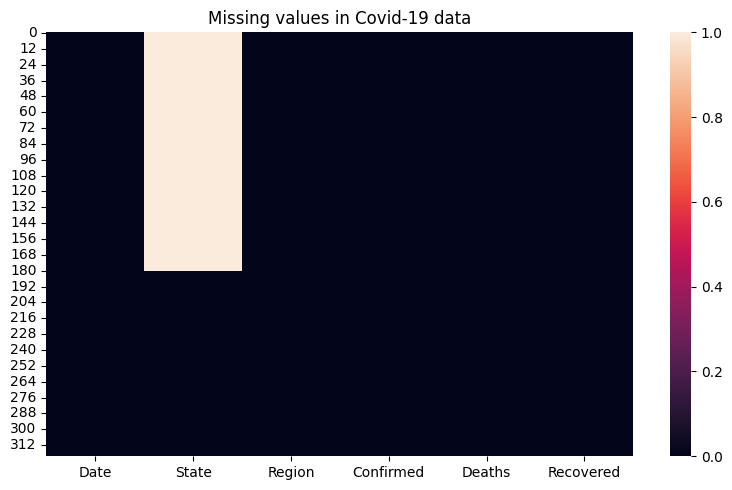

In [3]:
%matplotlib inline
plt.figure(figsize=(8, 5))
ax = sns.heatmap(covid.isnull(), cbar=True)
plt.title('Missing values in Covid-19 data')
plt.tight_layout()
plt.show()


## Q.4-1) Show the number of Confirmed, Deaths and Recovered cases in each Region.


In [4]:
covid.groupby('Region')[['Confirmed', 'Deaths', 'Recovered']].sum().sort_values('Confirmed', ascending=False)


,Confirmed,Deaths,Recovered
Region,,,
US,1039909,60967,120720
Spain,236899,24275,132929
Italy,203591,27682,71252
France,166543,24121,49118
UK,166441,26166,857
...,...,...,...
Sao Tome and Principe,8,0,4
Papua New Guinea,8,0,0
Bhutan,7,0,5


## Q.4-2) Remove all the records where the Confirmed Cases is Less Than 10.


In [5]:
print('Rows before:', covid.shape[0])
print('Rows with Confirmed < 10:', (covid.Confirmed < 10).sum())
covid = covid[~(covid.Confirmed < 10)]
print('Rows after removal:', covid.shape[0])
covid.head()


Rows before: 321
Rows with Confirmed < 10: 17
Rows after removal: 304


,Date,State,Region,Confirmed,Deaths,Recovered
0,4/29/2020,NaN,Afghanistan,1939,60,252
1,4/29/2020,NaN,Albania,766,30,455
2,4/29/2020,NaN,Algeria,3848,444,1702
3,4/29/2020,NaN,Andorra,743,42,423
4,4/29/2020,NaN,Angola,27,2,7


## Q.4-3) In which Region, maximum number of Confirmed cases were recorded ?


In [6]:
confirmed_by_region = covid.groupby('Region')['Confirmed'].sum().sort_values(ascending=False)
print(confirmed_by_region.head(10))
print('\nRegion with maximum Confirmed cases:', confirmed_by_region.idxmax(), int(confirmed_by_region.max()))


Region
US                1039909
Spain              236899
Italy              203591
France             166536
UK                 166432
Germany            161539
Turkey             117589
Russia              99399
Iran                93657
Mainland China      82861
Name: Confirmed, dtype: int64

Region with maximum Confirmed cases: US 1039909


## Q.4-4) In which Region, minimum number of Deaths cases were recorded ?


In [7]:
deaths_by_region = covid.groupby('Region')['Deaths'].sum().sort_values(ascending=True)
print(deaths_by_region.head(20))
print('\nRegion with minimum Deaths:', deaths_by_region.idxmin(), int(deaths_by_region.min()))


Region
Cambodia                            0
Seychelles                          0
Saint Lucia                         0
Central African Republic            0
Saint Kitts and Nevis               0
South Sudan                         0
Rwanda                              0
Grenada                             0
Macau                               0
Madagascar                          0
Nepal                               0
Namibia                             0
Saint Vincent and the Grenadines    0
Mozambique                          0
Holy See                            0
Timor-Leste                         0
Mongolia                            0
Uganda                              0
Laos                                0
Eritrea                             0
Name: Deaths, dtype: int64

Region with minimum Deaths: Cambodia 0


## Q.4-5) How many Confirmed, Deaths & Recovered cases were reported from India till 29 April 2020 ?


In [8]:
covid[covid.Region == 'India']


,Date,State,Region,Confirmed,Deaths,Recovered
74,4/29/2020,NaN,India,33062,1079,8437


## Q.4-6-A) Sort the entire data wrt No. of Confirmed cases in ascending order.


In [9]:
covid.sort_values(by='Confirmed', ascending=True)


,Date,State,Region,Confirmed,Deaths,Recovered
156,4/29/2020,NaN,Suriname,10,1,8
70,4/29/2020,NaN,Holy See,10,0,2
59,4/29/2020,NaN,Gambia,10,1,8
318,4/29/2020,Yukon,Canada,11,0,0
217,4/29/2020,Greenland,Denmark,11,0,11
...,...,...,...,...,...,...
57,4/29/2020,NaN,France,165093,24087,48228
168,4/29/2020,NaN,UK,165221,26097,0
80,4/29/2020,NaN,Italy,203591,27682,71252
153,4/29/2020,NaN,Spain,236899,24275,132929


## Q.4-6-B) Sort the entire data wrt No. of Recovered cases in descending order.


In [10]:
covid.sort_values(by='Recovered', ascending=False)


,Date,State,Region,Confirmed,Deaths,Recovered
153,4/29/2020,NaN,Spain,236899,24275,132929
61,4/29/2020,NaN,Germany,161539,6467,120400
76,4/29/2020,NaN,Iran,93657,5957,73791
80,4/29/2020,NaN,Italy,203591,27682,71252
229,4/29/2020,Hubei,Mainland China,68128,4512,63616
...,...,...,...,...,...,...
258,4/29/2020,Nevada,US,4934,230,0
257,4/29/2020,Nebraska,US,3851,56,0
255,4/29/2020,Montana,US,451,16,0
254,4/29/2020,Missouri,US,7660,338,0
